# Home assigment 1

Please give your name below:

In [55]:
name='Lê Huỳnh Thiện Nhân'

## Exercise 1

In nature Uranium is commonly available in the form of two isotopes: $^{235}U$ and $^{238}U$. Let us define Uranium enrichment as:
\begin{equation}
\epsilon= \frac{N_{^{235}U}}{N_{^{235}U}+N_{^{238}U}}
\end{equation}

where $N$ indicates the number of atoms in a given volume. The half-lives are $4.51 \times 10^9$ and $7.13 \times 10^8$ yr for $^{238}U$ and $^{235}U$, respectively. Today, the natural enrichment is $0.72 \%$, whereas a typical LWR fuel has an enrichment of $2-5 w\%$. It is notable that in the past natural uranium contained enough $^{235}U$ that LWRs could have been built without requiring further enrichment. In fact, evidance shows that cca $1.7 \times 10^9$ yr ago at certain locations such as in Oklo, Gabon the conditions were ideal for the formation of [natural nuclear fission reactors](https://en.wikipedia.org/wiki/Natural_nuclear_fission_reactor). 

- Derive the equation that describes the evolution of the enrichment in time. (hint: use markdown and Latex to document your derivation)
- Define a program function which evaluates the enrichment at a certain time in the past. The function should be able to handle array-like inputs (hint: you can use numpy). 
- Evaluate the function and print the enrichment 
    - at the birth of Earth ($4.5 \times 10^9$ years ago)
    - at the time when the Oklo reactor "operated" ($1.7 \times 10^9$ years ago)
- Plot the enrichment of uranium versus time in the past. Include a vertical line (`plt.axvline`) at the two times highlighted above


### Solution

Let the time origin of the function be the birth of Earth, ie. $4.5\cdot 10^9$ years ago, define the number of U-235 and U-238 isotopes at that time to be $N_{0235}$ and $N_{0238}$

We have the equation:
$$\begin{cases}
N_{235} = N_{0235}\cdot 2^{-\frac{t}{T_{235}}}\\
N_{238} = N_{0238}\cdot 2^{-\frac{t}{T_{238}}}
\end{cases}$$
With t being the time since the birth of Earth.
We may evaluate the uranium enrichment as a function of time:
$$\Rightarrow \epsilon = \frac{N_{0235}\cdot 2^{-\frac{t}{T_{235}}}}{N_{0235}\cdot 2^{-\frac{t}{T_{235}}}+N_{0238}\cdot 2^{-\frac{t}{T_{238}}}}$$
Define the fraction $\frac{N_{0238}}{N_{0235}} = \alpha$, $\epsilon$ becomes:
$$\epsilon = \frac{2^{-\frac{t}{T_{235}}}}{2^{-\frac{t}{T_{235}}}+\alpha\cdot 2^{-\frac{t}{T_{238}}}}$$
Today, the natural enrichment is $0.72$%, plugging in $t = 4.5\cdot 10^9$ years:
$$\Rightarrow 0.0072 = \frac{2^{-\frac{4.5\cdot 10^9}{7.13\cdot 10^8}}}{2^{-\frac{4.5\cdot 10^9}{7.13\cdot 10^8}}+\alpha\cdot 2^{-\frac{4.5\cdot 10^9}{4.51\cdot 10^9}}}$$
Now we can solve for $\alpha$:

$$\alpha = \frac{(1-0.0072)\cdot2^{-\frac{4.5\cdot 10^9}{7.13\cdot 10^8}}}{0.0072\cdot 2^{-\frac{4.5\cdot 10^9}{4.51\cdot 10^9}}} \approx 3.46723267619$$

To make it easier to handle, we can turn the epsilon function $\epsilon(t)$ into dependent on $\tau$ defined as the point in time in the past, for example if one wants to find $\epsilon$ at 3 billion years ago, you can plug in $\tau = 3\cdot 10^9$ years:
$$\epsilon (\tau) = \frac{2^{-\frac{4.5\cdot 10^9 -\tau}{7.13\cdot 10^8}}}{2^{-\frac{4.5\cdot 10^9 -\tau}{7.13\cdot 10^8}} + \alpha \cdot 2^{-\frac{4.5\cdot 10^9 -\tau}{4.51\cdot 10^9}}}$$

In [32]:
import numpy as np
import matplotlib.pyplot as plt
# include your code here

def epsilon(t):
    """Function to evaluate Uranium enrichment at time t. The parameter t can be both float or array."""
    T_235 = 7.13*(10**8) 
    T_238 = 4.51*(10**9)
    T_Uni = 4.5*(10**9)
    alpha = (1-0.0072)*(2**(-(T_Uni)/(T_235)))/(0.0072*(2**(-(T_Uni)/(T_238))))
    eps = (2**(-(T_Uni-t)/(T_235)))/(2**(-(T_Uni-t)/(T_235))+alpha*2**(-(T_Uni-t)/(T_238)))
    return eps
#do the printing and plotting here

The enrichment at the birth of Earth is:  0.22385223078458702
The enrichment at the time when the Oklo reactor "operated":  0.028331013449302354
The plot for the enrichment of uranium versus time in the past:


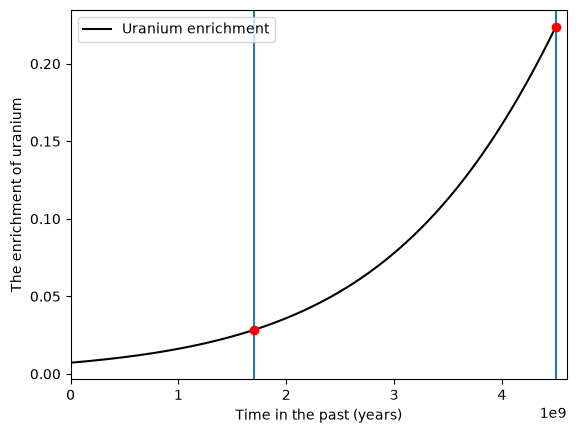

In [54]:
print('The enrichment at the birth of Earth is: ', epsilon(4.5*10**9))
print('The enrichment at the time when the Oklo reactor "operated": ', epsilon(1.7*10**9))
print('The plot for the enrichment of uranium versus time in the past:')

time = np.linspace(0,4.5*10**9,1000)
enrichment = epsilon(time)
plt.figure()
plt.plot(time,enrichment, 'k-', label='Uranium enrichment')
plt.xlabel('Time in the past (years)')
plt.legend()
plt.ylabel('The enrichment of uranium')
plt.xlim(0,4.6*10**9)
plt.axvline(4.5*10**9,-10,10)
plt.axvline(1.7*10**9,-10,10)
plt.plot(1.7*10**9,epsilon(1.7*10**9),'ro')
plt.plot(4.5*10**9,epsilon(4.5*10**9),'ro')
plt.show()